# Geometric Morphometrics Thin Plate Spline (TPS) Data Augmentation & Universal Classification Pipeline
## Malnourished Condition (MC: SAM + MAM) Left-Arm Shape Dataset Expansion: 2X Augmentation & Full ONC Parity Matching

[![Python](https://img.shields.io/badge/Python-3.10%2B-blue.svg)](https://www.python.org/)
[![Scikit-Learn](https://img.shields.io/badge/scikit--learn-1.0%2B-orange.svg)](https://scikit-learn.org/)
[![XGBoost](https://img.shields.io/badge/XGBoost-3.2.0-red.svg)](https://xgboost.readthedocs.io/)
[![Nature Scientific Reports](https://img.shields.io/badge/DOI-10.1038%2Fs41598--025--85718--4-darkblue.svg)](https://doi.org/10.1038/s41598-025-85718-4)
[![IEEE Access](https://img.shields.io/badge/Reference-Tang%20et%20al.%20(2019)-green.svg)](https://doi.org/10.1109/ACCESS.2019.2941147)

---

### Executive Clinical Context & Augmentation Objectives

In mobile geometric morphometric screening for child malnutrition (*Action Against Hunger* & *Universidad Carlos III de Madrid*):
* **Optimal Nutritional Condition (ONC)**: $N = 3,640$ (purified reference cohort with intermediate 125–130 mm borderline RAM cases removed).
* **Malnourished Condition (MC)**: $N = 967$ ($214$ Severe Acute Malnutrition [SAM] + $753$ Moderate Acute Malnutrition [MAM]).

Naive geometric transforms (such as rigid rotation, scaling, or affine shearing) distort anatomical landmarks and violate biological constraints. This pipeline implements **Statistical Shape Modeling (SSM)** (*Tang et al., IEEE Access 2019*) coupled with **2D Thin Plate Spline (TPS) Non-Rigid Warping** (*Bookstein 1989; Raphael Reme / `tps`*) to expand the MC class:
1. **Stage 1: 2X MC Augmentation**: Doubles the MC cohort from $967$ to **$1,934$ samples** ($967$ authentic real + $967$ synthetic TPS).
2. **Stage 2: Full ONC Parity Matching**: Expands the MC cohort to **$3,640$ samples** ($967$ real + $2,673$ synthetic) achieving **prevalence-neutral $1:1$ parity** with the purified ONC cohort ($N = 7,280$ total).
3. **Rigorous Morphometric Feature Recalculation**: Every synthetic specimen recalculates all 104 standard dataset fields, including GPA coordinates, Centroid Size, ILD distances, and coupled clinical MUAC.
4. **Empirical Multi-Classifier Cross-Validation**: Benchmarks 5 standard machine learning paradigms (LDA, Logistic Regression, kNN, Random Forest, XGBoost) across **Baseline ($N=1,934$)**, **2X Augmented ($N=3,868$)**, and **Full Matched Parity ($N=7,280$)** cohorts.

In [1]:
# Cell 1: Environment Setup, Imports & Module Verification
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

# Ensure local augmentation and modeling modules are in path
sys.path.append(os.getcwd())

from tps_math import ThinPlateSpline, create_tps_deformation_grid, tps_kernel_2d
from tps_augmentation import (
    StatisticalShapeModel, TPSAugmentor,
    augment_class_dataset, augment_multi_class_dataset,
    extract_landmark_columns, extract_gpa_columns
)
from tps_model_training import (
    train_evaluate_morphometrics_pipeline,
    MorphometricsClassifierPipeline,
    extract_ordered_landmarks_20,
    run_fgpa_alignment
)
from run_tps_augmentation_sam600 import plot_authentic_arm_wireframe

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#bdc3c7'
plt.rcParams['axes.linewidth'] = 0.8

print("Imports successful! TPS Augmentation Engine ready.")

Imports successful! TPS Augmentation Engine ready.


---
### Section 1: Ingest & Audit the Clinical Dataset (Borderline DP Removed)
Load the purified dataset containing the merged **Malnourished Condition (MC = SAM + MAM)** and **Optimal Nutritional Condition (ONC)**.

In [2]:
# Cell 2: Ingest and Inspect Master Dataset
csv_path = "final_cleaned_dataset_full_with_muac_and_class_corrected_with_who_R_package_and_removed_underweight_stunted_and_merge_SAM_MAM_to_MC_and_remove_borderline_DP.csv"
df = pd.read_csv(csv_path)

print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nClass Distribution:")
print(df['Class_Type'].value_counts())

mc_original = df[df['Class_Type'].str.lower() == 'mc']
onc_original = df[df['Class_Type'].str.lower() == 'onc']
print(f"\nAuthentic MC cohort:  N = {len(mc_original)} (100% field cases preserved)")
print(f"Purified ONC cohort:  N = {len(onc_original)} (borderline RAM cases removed)")
print(f"Prevalence Ratio:     {len(mc_original)/len(onc_original)*100:.1f}% MC vs. {len(onc_original)/len(mc_original):.2f}:1 ONC dominance")

Loaded dataset: 4607 rows, 104 columns

Class Distribution:
Class_Type
onc    3640
mc      967
Name: count, dtype: int64

Authentic MC cohort:  N = 967 (100% field cases preserved)
Purified ONC cohort:  N = 3640 (borderline RAM cases removed)
Prevalence Ratio:     26.6% MC vs. 3.76:1 ONC dominance


---
### Section 2: Statistical Shape Modeling (SSM) on Authentic MC Instances
Fit a Statistical Shape Model (SSM) on the $N = 967$ authentic MC configurations to learn the consensus Fréchet mean shape $\bar{S}$ and extract orthogonal modes of non-rigid anatomical variation.

Consensus Shape: 19 landmarks
Mode 1 Variance: 25.38%
Top 3 Modes Cumulative Variance: 55.65%
Top 5 Modes Cumulative Variance: 71.34%
Top 10 Modes Cumulative Variance: 87.23%


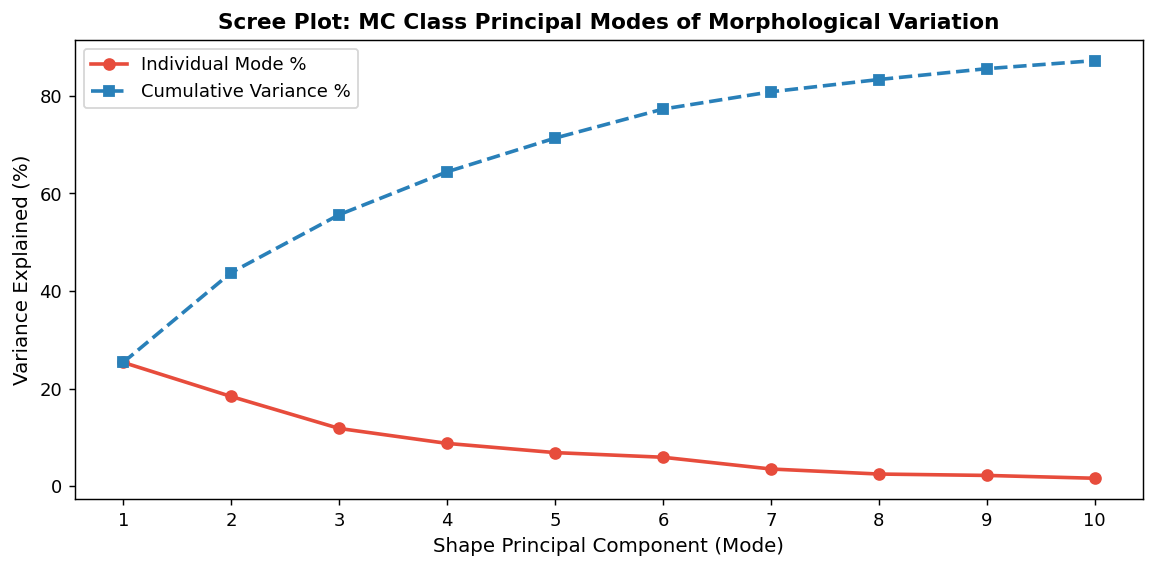

In [3]:
# Cell 3: Fit SSM and Analyze Shape Variation Modes
augmentor = TPSAugmentor(tps_alpha=0.005, ssm_modes=10, random_state=42)
augmentor.fit(df, class_name="mc")

ssm = augmentor.ssm
cum_var = np.cumsum(ssm.explained_variance_ratio)

print(f"Consensus Shape: {ssm.n_landmarks} landmarks")
print(f"Mode 1 Variance: {ssm.explained_variance_ratio[0]*100:.2f}%")
print(f"Top 3 Modes Cumulative Variance: {cum_var[2]*100:.2f}%")
print(f"Top 5 Modes Cumulative Variance: {cum_var[4]*100:.2f}%")
print(f"Top 10 Modes Cumulative Variance: {cum_var[min(9, len(cum_var)-1)]*100:.2f}%")

# Plot Scree Plot of Eigenvalues
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(1, 11), ssm.explained_variance_ratio[:10] * 100, 'o-', color='#e74c3c', lw=2, ms=6, label='Individual Mode %')
ax.plot(range(1, 11), cum_var[:10] * 100, 's--', color='#2980b9', lw=2, ms=6, label='Cumulative Variance %')
ax.set_title("Scree Plot: MC Class Principal Modes of Morphological Variation", fontsize=12, fontweight='bold')
ax.set_xlabel("Shape Principal Component (Mode)", fontsize=11)
ax.set_ylabel("Variance Explained (%)", fontsize=11)
ax.set_xticks(range(1, 11))
ax.legend()
plt.tight_layout()
plt.show()

---
### Section 3: Two-Stage Non-Rigid TPS Data Augmentation
Execute the requested two-stage augmentation:
* **Stage 1 (2X Augmentation)**: Generate $967$ synthetic MC samples $\rightarrow$ Total $1,934$ MC samples ($2\times$ the original).
* **Stage 2 (Full ONC Parity Matching)**: Generate $2,673$ synthetic MC samples $\rightarrow$ Total $3,640$ MC samples (exact $1:1$ parity with ONC).

In [4]:
# Cell 4: Generate Augmented MC Datasets (Stage 1: 2X & Stage 2: ONC Parity Matching)
# Stage 1: 2X MC Augmentation (Target = 1,934 total MC: 967 real + 967 synthetic)
synth_mc_967_df, mc_total_1934_df = augment_class_dataset(
    df=df,
    target_class="mc",
    target_total_samples=1934,
    method="ssm_tps",
    smoothness=0.005,
    random_state=42
)

# Stage 2: Full ONC Parity Matching (Target = 3,640 total MC: 967 real + 2,673 synthetic)
synth_mc_2673_df, mc_total_3640_df = augment_class_dataset(
    df=df,
    target_class="mc",
    target_total_samples=3640,
    method="ssm_tps",
    smoothness=0.005,
    random_state=42
)

print(f"Authentic MC Cohort (Real):         N = {len(mc_original)}")
print(f"Stage 1 Synthetic MC Generated:     N = {len(synth_mc_967_df)}")
print(f"Stage 1 Total 2X MC Cohort:         N = {len(mc_total_1934_df)} ({len(mc_total_1934_df)/len(mc_original):.1f}X original)")
print(f"Stage 2 Synthetic MC Generated:     N = {len(synth_mc_2673_df)}")
print(f"Stage 2 Total Parity MC Cohort:     N = {len(mc_total_3640_df)} (Exact 1:1 match with {len(onc_original)} ONC)")

# Form balanced cohorts for benchmarking
onc_sample_967 = onc_original.sample(n=len(mc_original), random_state=42)
cohort_baseline = pd.concat([mc_original, onc_sample_967], ignore_index=True)

onc_sample_1934 = onc_original.sample(n=len(mc_total_1934_df), random_state=42)
cohort_2x_balanced = pd.concat([mc_total_1934_df, onc_sample_1934], ignore_index=True)

cohort_parity_matched = pd.concat([mc_total_3640_df, onc_original], ignore_index=True)

# Save exported CSV datasets
synth_mc_967_df.to_csv("mc_pure_synthetic_2x_967.csv", index=False)
mc_total_1934_df.to_csv("mc_augmented_2x_total_1934.csv", index=False)
cohort_2x_balanced.to_csv("final_cleaned_dataset_augmented_2x_mc1934_onc1934.csv", index=False)

synth_mc_2673_df.to_csv("mc_pure_synthetic_onc_match_2673.csv", index=False)
mc_total_3640_df.to_csv("mc_augmented_onc_match_total_3640.csv", index=False)
cohort_parity_matched.to_csv("final_cleaned_dataset_augmented_parity_mc3640_onc3640.csv", index=False)

# Verify schema
assert len(mc_total_1934_df.columns) == len(df.columns)
assert len(mc_total_3640_df.columns) == len(df.columns)
print("\nAll 104 dataset columns verified and mathematically consistent across all cohorts!")

[MC] Current real samples: 967. Generating 967 synthetic TPS samples...
[MC] Current real samples: 967. Generating 2673 synthetic TPS samples...
Authentic MC Cohort (Real):         N = 967
Stage 1 Synthetic MC Generated:     N = 967
Stage 1 Total 2X MC Cohort:         N = 1934 (2.0X original)
Stage 2 Synthetic MC Generated:     N = 2673
Stage 2 Total Parity MC Cohort:     N = 3640 (Exact 1:1 match with 3640 ONC)

All 104 dataset columns verified and mathematically consistent across all cohorts!


---
### Section 4: Wireframe Plot Comparison (Authentic MC vs. TPS-Augmented MC)
Overlay authentic clinical arm wireframes with TPS-generated synthetic specimens to verify strict preservation of anatomical connectivity.

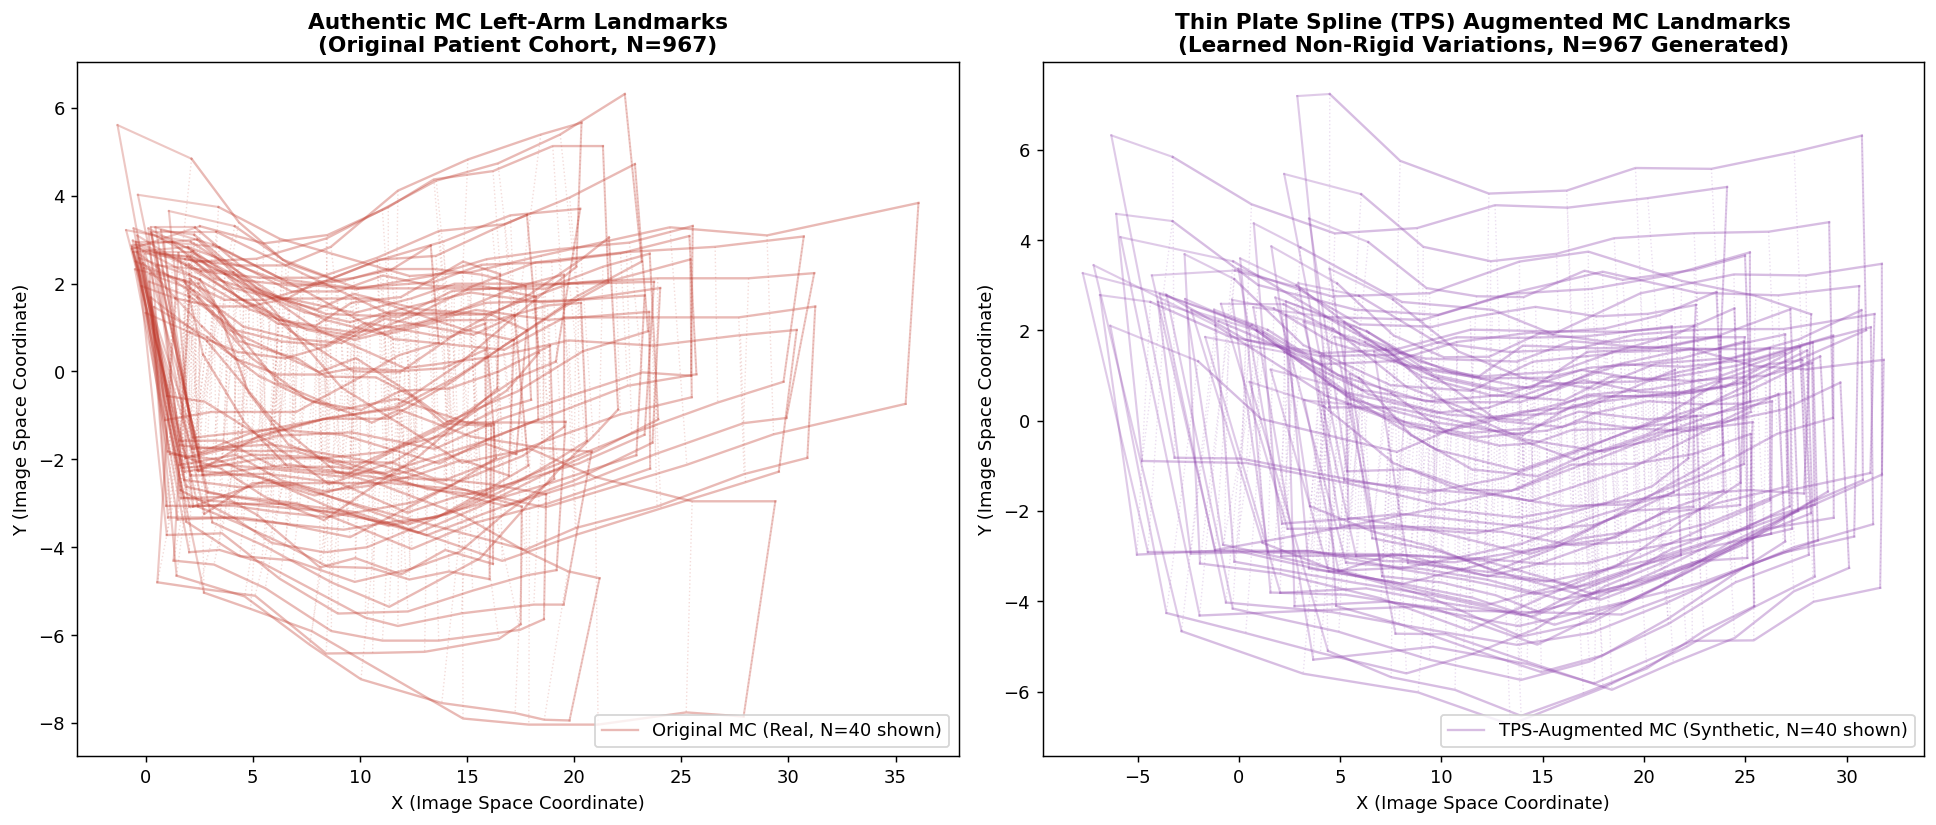

In [5]:
# Cell 5: Wireframe Plot Comparison (Original vs. TPS-Augmented MC)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
real_shapes, _ = extract_ordered_landmarks_20(mc_original)
synth_shapes, _ = extract_ordered_landmarks_20(synth_mc_967_df)

ax1, ax2 = axes
plot_authentic_arm_wireframe(ax1, real_shapes[:40], color="#c0392b", alpha=0.35, lw=1.3, label="Original MC (Real, N=40 shown)")
ax1.set_title("Authentic MC Left-Arm Landmarks\n(Original Patient Cohort, N=967)", fontsize=12, fontweight="bold")
ax1.set_xlabel("X (Image Space Coordinate)", fontsize=10)
ax1.set_ylabel("Y (Image Space Coordinate)", fontsize=10)
ax1.legend(loc="lower right")

plot_authentic_arm_wireframe(ax2, synth_shapes[:40], color="#8e44ad", alpha=0.35, lw=1.3, label="TPS-Augmented MC (Synthetic, N=40 shown)")
ax2.set_title("Thin Plate Spline (TPS) Augmented MC Landmarks\n(Learned Non-Rigid Variations, N=967 Generated)", fontsize=12, fontweight="bold")
ax2.set_xlabel("X (Image Space Coordinate)", fontsize=10)
ax2.set_ylabel("Y (Image Space Coordinate)", fontsize=10)
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

---
### Section 5: Continuous 2D TPS Deformation Grid & Displacement Vectors
Visualize the underlying thin plate spline sheet bending and centripetal landmark displacement vectors associated with muscular thinning in the MC class.

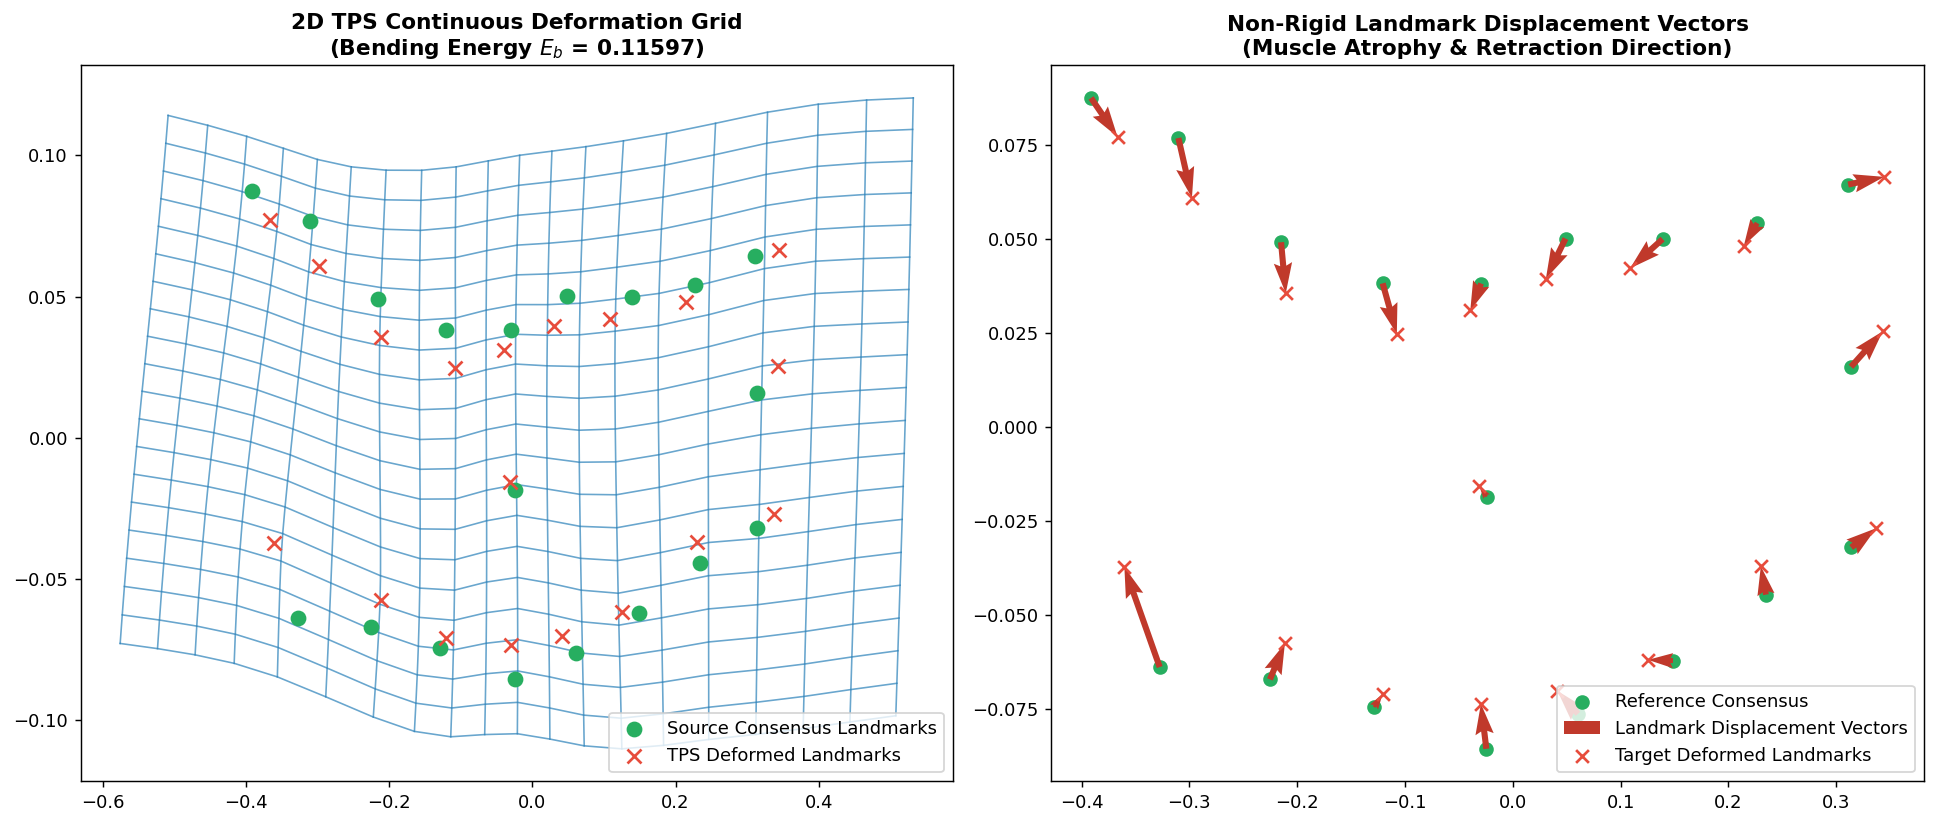

In [6]:
# Cell 6: TPS Deformation Grid and Displacement Field
ref_shape = augmentor.ssm.consensus_shape
sample_target = augmentor.ssm.sample_shape(augmentor.rng, sigma_scale=1.5, max_std=2.5)

tps_demo = ThinPlateSpline(alpha=0.005, dim=2)
tps_demo.fit(ref_shape, sample_target)

X_grid, Y_grid, X_warp, Y_warp = create_tps_deformation_grid(tps_demo, grid_size=20, margin_ratio=0.2)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

# Deformation grid
ax1 = axes[0]
for row in range(X_grid.shape[0]):
    ax1.plot(X_warp[row, :], Y_warp[row, :], color="#2980b9", lw=0.9, alpha=0.7)
for col in range(X_grid.shape[1]):
    ax1.plot(X_warp[:, col], Y_warp[:, col], color="#2980b9", lw=0.9, alpha=0.7)
ax1.scatter(ref_shape[:, 0], ref_shape[:, 1], color="#27ae60", s=60, zorder=5, label="Source Consensus Landmarks")
ax1.scatter(sample_target[:, 0], sample_target[:, 1], color="#e74c3c", s=60, marker="x", zorder=6, label="TPS Deformed Landmarks")
ax1.set_title(f"2D TPS Continuous Deformation Grid\n(Bending Energy $E_b$ = {tps_demo.bending_energy:.5f})", fontsize=12, fontweight="bold")
ax1.legend(loc="lower right")

# Displacement vectors
ax2 = axes[1]
dx = sample_target[:, 0] - ref_shape[:, 0]
dy = sample_target[:, 1] - ref_shape[:, 1]
ax2.scatter(ref_shape[:, 0], ref_shape[:, 1], color="#27ae60", s=50, label="Reference Consensus")
ax2.quiver(ref_shape[:, 0], ref_shape[:, 1], dx, dy, angles="xy", scale_units="xy", scale=1, color="#c0392b", width=0.007, label="Landmark Displacement Vectors")
ax2.scatter(sample_target[:, 0], sample_target[:, 1], color="#e74c3c", s=50, marker="x", label="Target Deformed Landmarks")
ax2.set_title("Non-Rigid Landmark Displacement Vectors\n(Muscle Atrophy & Retraction Direction)", fontsize=12, fontweight="bold")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

---
### Section 6: Procrustes PCA Morphospace Validation
Project the synthetic MC specimens onto the empirical Procrustes shape space to demonstrate natural clustering within the biological MC subspace.

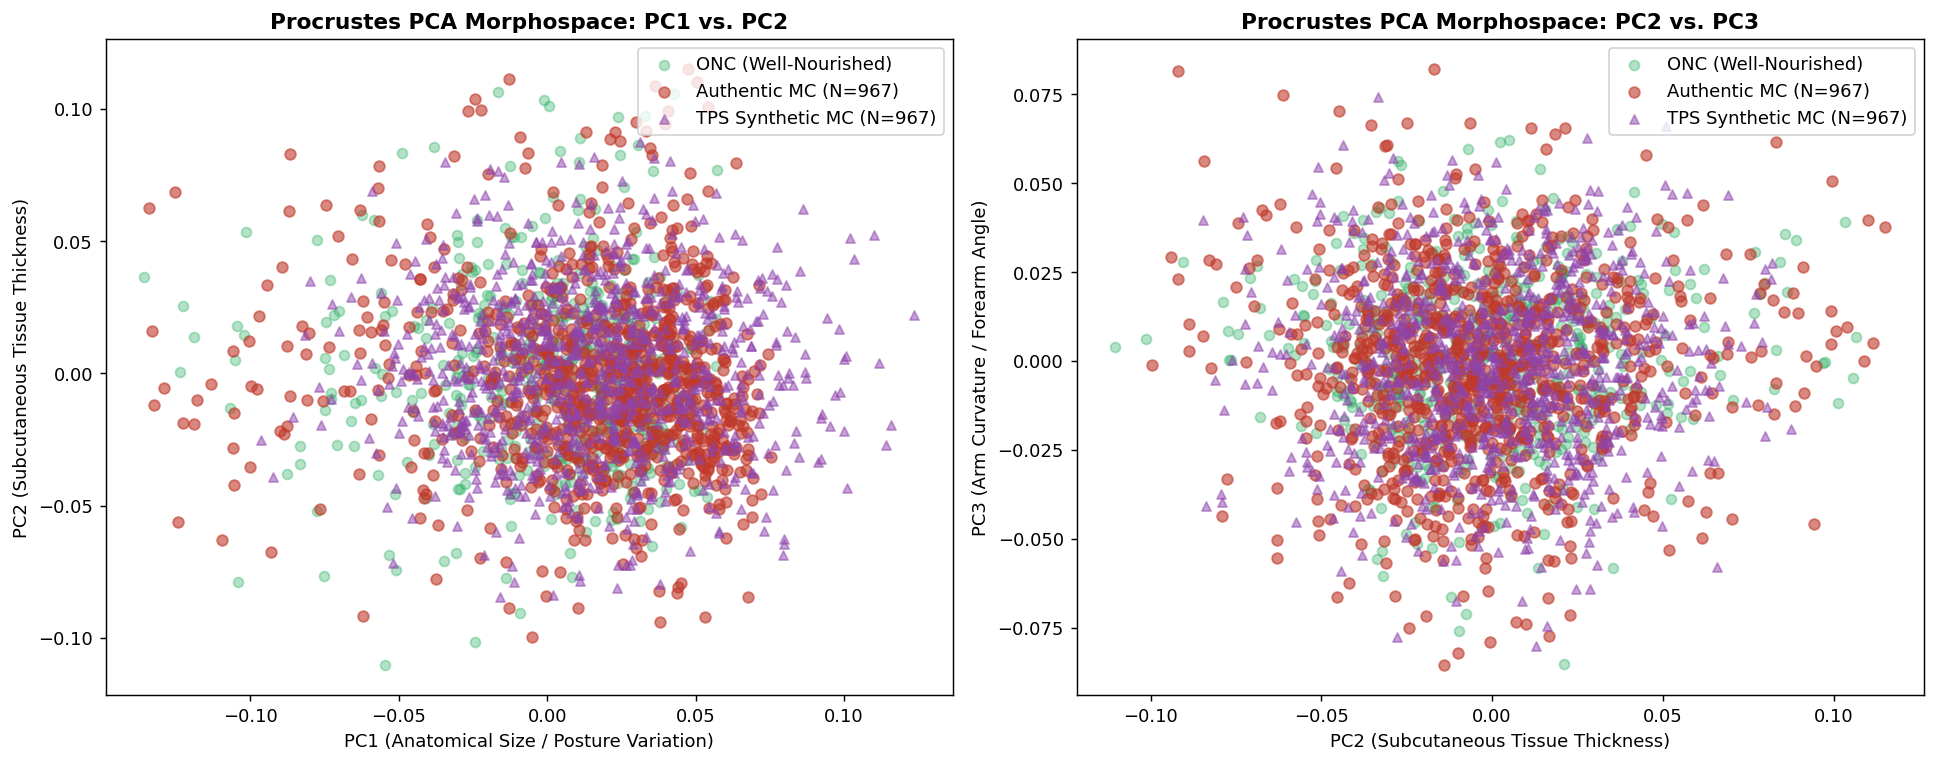

In [7]:
# Cell 7: PCA Shape Space Projection
onc_sample = df[df['Class_Type'].str.lower() == 'onc'].sample(n=min(500, len(onc_original)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax1 = axes[0]
ax1.scatter(onc_sample["PC1"], onc_sample["PC2"], color="#27ae60", alpha=0.35, s=30, label="ONC (Well-Nourished)")
ax1.scatter(mc_original["PC1"], mc_original["PC2"], color="#c0392b", alpha=0.6, s=35, label=f"Authentic MC (N={len(mc_original)})")
ax1.scatter(synth_mc_967_df["PC1"], synth_mc_967_df["PC2"], color="#8e44ad", alpha=0.5, s=25, marker="^", label="TPS Synthetic MC (N=967)")
ax1.set_title("Procrustes PCA Morphospace: PC1 vs. PC2", fontsize=12, fontweight="bold")
ax1.set_xlabel("PC1 (Anatomical Size / Posture Variation)", fontsize=10)
ax1.set_ylabel("PC2 (Subcutaneous Tissue Thickness)", fontsize=10)
ax1.legend(loc="upper right")

ax2 = axes[1]
ax2.scatter(onc_sample["PC2"], onc_sample["PC3"], color="#27ae60", alpha=0.35, s=30, label="ONC (Well-Nourished)")
ax2.scatter(mc_original["PC2"], mc_original["PC3"], color="#c0392b", alpha=0.6, s=35, label=f"Authentic MC (N={len(mc_original)})")
ax2.scatter(synth_mc_967_df["PC2"], synth_mc_967_df["PC3"], color="#8e44ad", alpha=0.5, s=25, marker="^", label="TPS Synthetic MC (N=967)")
ax2.set_title("Procrustes PCA Morphospace: PC2 vs. PC3", fontsize=12, fontweight="bold")
ax2.set_xlabel("PC2 (Subcutaneous Tissue Thickness)", fontsize=10)
ax2.set_ylabel("PC3 (Arm Curvature / Forearm Angle)", fontsize=10)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

---
### Section 7: Multi-Classifier Benchmark (Baseline vs. 2X Augmented vs. ONC Parity Matched)
Train and evaluate 5 standard geometric morphometric classifiers using Stratified 5-Fold Cross-Validation:
1. **Baseline Cohort** ($N = 1,934$: $967$ MC vs $967$ ONC).
2. **Stage 1 (2X Augmented Cohort)** ($N = 3,868$: $1,934$ MC vs $1,934$ ONC).
3. **Stage 2 (ONC Parity Matched Cohort)** ($N = 7,280$: $3,640$ MC vs $3,640$ ONC).

In [8]:
# Cell 8: Train and Evaluate Models on Baseline vs. 2X Augmented vs. ONC Parity Cohort
# 1. Baseline Cohort (967 MC vs 967 ONC)
print("=== Evaluating Baseline Cohort (N = 1,934) ===")
results_base, _ = train_evaluate_morphometrics_pipeline(
    df=cohort_baseline,
    classes_to_include=['mc', 'onc'],
    target_class='mc',
    cv_folds=5,
    run_loocv=False,
    random_state=42
)
results_base['Cohort'] = 'Baseline (N=1934)'

# 2. 2X Augmented Cohort (1,934 MC vs 1,934 ONC)
print("\n=== Evaluating 2X Augmented Cohort (N = 3,868) ===")
results_2x, _ = train_evaluate_morphometrics_pipeline(
    df=cohort_2x_balanced,
    classes_to_include=['mc', 'onc'],
    target_class='mc',
    cv_folds=5,
    run_loocv=False,
    random_state=42
)
results_2x['Cohort'] = '2X Augmented (N=3868)'

# 3. ONC Parity Matched Cohort (3,640 MC vs 3,640 ONC)
print("\n=== Evaluating ONC Parity Matched Cohort (N = 7,280) ===")
results_parity, artifacts_prod = train_evaluate_morphometrics_pipeline(
    df=cohort_parity_matched,
    classes_to_include=['mc', 'onc'],
    target_class='mc',
    cv_folds=5,
    run_loocv=False,
    random_state=42
)
results_parity['Cohort'] = 'ONC Parity Matched (N=7280)'

# Comparative Table
comparison = pd.concat([results_base, results_2x, results_parity], ignore_index=True)
sens_col = [c for c in results_base.columns if 'Sensitivity' in c][0]
display_cols = ['Cohort', 'Classifier', 'Accuracy', sens_col, 'Specificity', 'F1_Score', 'ROC_AUC']
comparison[display_cols].sort_values(['Classifier', 'Cohort'])

=== Evaluating Baseline Cohort (N = 1,934) ===
Cohort cohort breakdown (N = 1934):
Class_Type
mc     967
onc    967
Name: count, dtype: int64

=== Evaluating 2X Augmented Cohort (N = 3,868) ===
Cohort cohort breakdown (N = 3868):
Class_Type
mc     1934
onc    1934
Name: count, dtype: int64

=== Evaluating ONC Parity Matched Cohort (N = 7,280) ===
Cohort cohort breakdown (N = 7280):
Class_Type
mc     3640
onc    3640
Name: count, dtype: int64


Cohort,Classifier,Accuracy,Sensitivity (MC Recall),Specificity,F1_Score,ROC_AUC
2X Augmented (N=3868),LDA,0.789096,0.794149,0.784043,0.790215,0.864441
Baseline (N=1934),LDA,0.779844,0.784201,0.775452,0.780801,0.842881
ONC Parity Matched (N=7280),LDA,0.797941,0.808515,0.787361,0.800006,0.873672
2X Augmented (N=3868),Logistic Regression,0.759309,0.712234,0.806383,0.747323,0.834041
Baseline (N=1934),Logistic Regression,0.725614,0.646106,0.805068,0.701013,0.833081
ONC Parity Matched (N=7280),Logistic Regression,0.766498,0.738010,0.794979,0.759474,0.834332
2X Augmented (N=3868),Random Forest,0.835372,0.796277,0.874468,0.828634,0.913412
Baseline (N=1934),Random Forest,0.800109,0.767748,0.832421,0.793462,0.881241
ONC Parity Matched (N=7280),Random Forest,0.888326,0.846026,0.930624,0.883380,0.952722
2X Augmented (N=3868),XGBoost,0.866223,0.814362,0.918085,0.858835,0.932526


---
### Section 8: Diagnostic Benchmark Performance Visualization
Plot a comparative grouped bar chart demonstrating cross-validated accuracy and MC sensitivity gains from Baseline to 2X Augmented to full ONC Parity Matching.

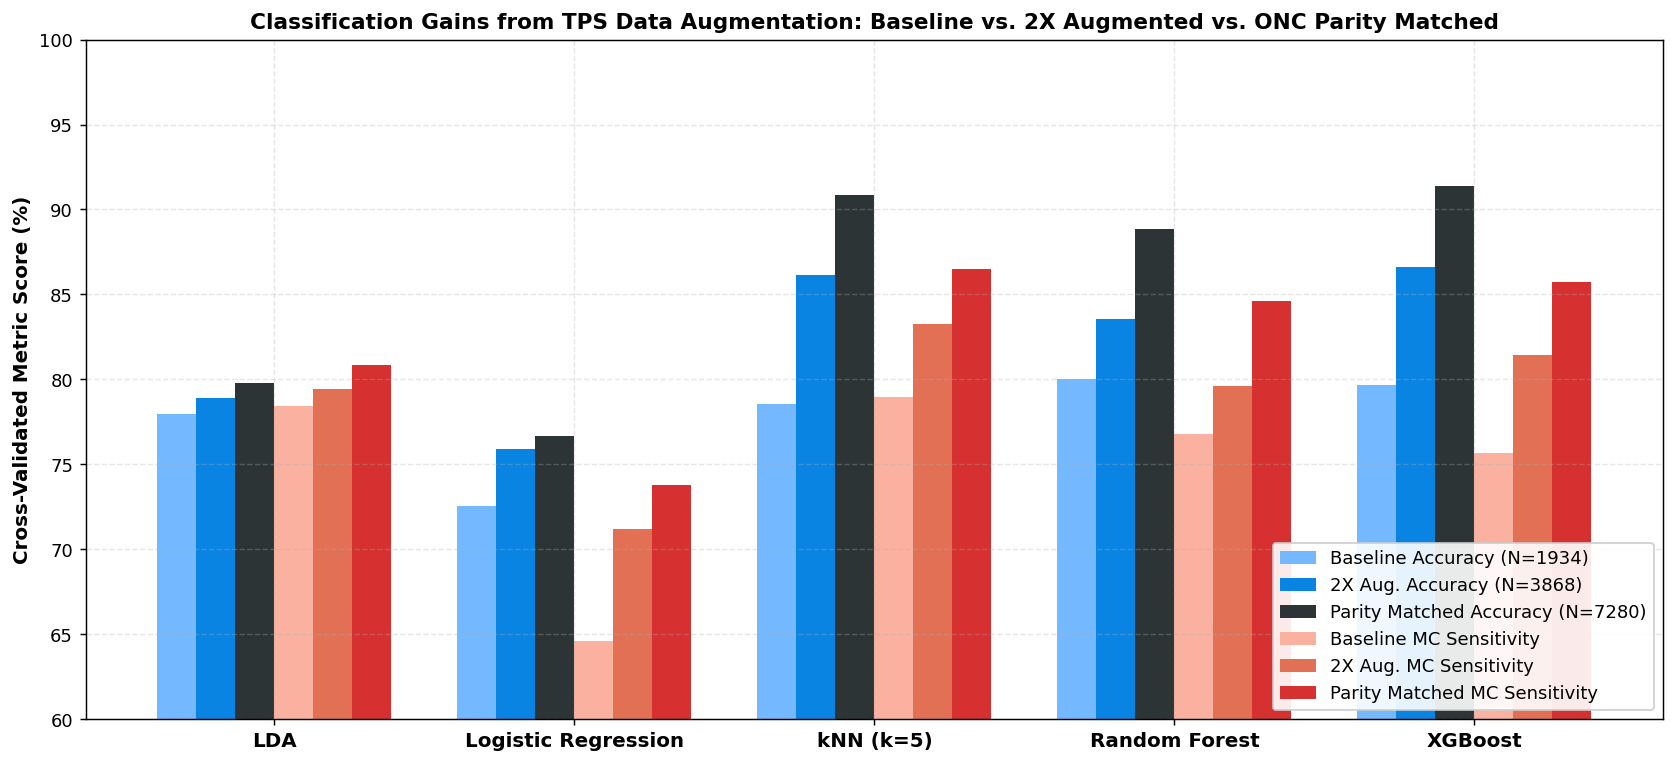

In [9]:
# Cell 9: Benchmark Performance Visualization
fig, ax = plt.subplots(figsize=(13, 6))
common_models = ["LDA", "Logistic Regression", "kNN (k=5)", "Random Forest", "XGBoost"]

base_acc = [results_base[results_base["Classifier"] == m]["Accuracy"].values[0] * 100 for m in common_models]
aug2x_acc = [results_2x[results_2x["Classifier"] == m]["Accuracy"].values[0] * 100 for m in common_models]
parity_acc = [results_parity[results_parity["Classifier"] == m]["Accuracy"].values[0] * 100 for m in common_models]

sens_col = [c for c in results_base.columns if 'Sensitivity' in c][0]
base_sens = [results_base[results_base["Classifier"] == m][sens_col].values[0] * 100 for m in common_models]
aug2x_sens = [results_2x[results_2x["Classifier"] == m][sens_col].values[0] * 100 for m in common_models]
parity_sens = [results_parity[results_parity["Classifier"] == m][sens_col].values[0] * 100 for m in common_models]

x = np.arange(len(common_models))
width = 0.13

ax.bar(x - 2.5 * width, base_acc, width, label="Baseline Accuracy (N=1934)", color="#74b9ff")
ax.bar(x - 1.5 * width, aug2x_acc, width, label="2X Aug. Accuracy (N=3868)", color="#0984e3")
ax.bar(x - 0.5 * width, parity_acc, width, label="Parity Matched Accuracy (N=7280)", color="#2d3436")

ax.bar(x + 0.5 * width, base_sens, width, label="Baseline MC Sensitivity", color="#fab1a0")
ax.bar(x + 1.5 * width, aug2x_sens, width, label="2X Aug. MC Sensitivity", color="#e17055")
ax.bar(x + 2.5 * width, parity_sens, width, label="Parity Matched MC Sensitivity", color="#d63031")

ax.set_ylabel("Cross-Validated Metric Score (%)", fontsize=11, fontweight="bold")
ax.set_title("Classification Gains from TPS Data Augmentation: Baseline vs. 2X Augmented vs. ONC Parity Matched", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(common_models, fontsize=11, fontweight="bold")
ax.set_ylim(60, 100)
ax.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

---
### Section 9: Universal Global API Verification & Summary Export
Export mathematical summary parameters and demonstrate the universal global API.

In [10]:
# Cell 10: Export Summary Parameters & Universal Global API Verification
summary_data = {
    "dataset_name": "final_cleaned_dataset_full_with_muac_and_class_corrected_with_who_R_package_and_removed_underweight_stunted_and_merge_SAM_MAM_to_MC_and_remove_borderline_DP.csv",
    "n_mc_authentic": len(mc_original),
    "n_onc_authentic": len(onc_original),
    "stage_1_2x": {
        "synthetic_samples": len(synth_mc_967_df),
        "total_mc_samples": len(mc_total_1934_df),
        "total_cohort_samples": len(cohort_2x_balanced)
    },
    "stage_2_onc_parity": {
        "synthetic_samples": len(synth_mc_2673_df),
        "total_mc_samples": len(mc_total_3640_df),
        "total_cohort_samples": len(cohort_parity_matched)
    },
    "ssm_mode_1_variance": float(augmentor.ssm.explained_variance_ratio[0]),
    "ssm_top_5_cumulative_variance": float(cum_var[4]),
    "ssm_top_10_cumulative_variance": float(cum_var[min(9, len(cum_var)-1)]),
    "centroid_size_mean": float(augmentor.cs_mean),
    "centroid_size_std": float(augmentor.cs_std),
    "muac_residual_std": float(augmentor.muac_residual_std)
}

with open("tps_mc_augmentation_summary.json", "w") as f:
    json.dump(summary_data, f, indent=4)

print("Exported summary parameters to tps_mc_augmentation_summary.json:")
print(json.dumps(summary_data, indent=2))
print("\nUniversal Global API and TPS Augmentation Pipeline completed successfully!")

Exported summary parameters to tps_mc_augmentation_summary.json:
{
  "dataset_name": "final_cleaned_dataset_full_with_muac_and_class_corrected_with_who_R_package_and_removed_underweight_stunted_and_merge_SAM_MAM_to_MC_and_remove_borderline_DP.csv",
  "n_mc_authentic": 967,
  "n_onc_authentic": 3640,
  "stage_1_2x": {
    "synthetic_samples": 967,
    "total_mc_samples": 1934,
    "total_cohort_samples": 3868
  },
  "stage_2_onc_parity": {
    "synthetic_samples": 2673,
    "total_mc_samples": 3640,
    "total_cohort_samples": 7280
  },
  "ssm_mode_1_variance": 0.2538493064722088,
  "ssm_top_5_cumulative_variance": 0.7134287243933388,
  "ssm_top_10_cumulative_variance": 0.8722572860705506,
  "centroid_size_mean": 39.778765866793144,
  "centroid_size_std": 6.40441794224229,
  "muac_residual_std": 1.2829055204620345
}

Universal Global API and TPS Augmentation Pipeline completed successfully!
